# Práctica 3 – Tarea 1: Contar el dinero en una imagen de monedas
Pipeline (sin aprendizaje profundo):
1. Segmentación (umbralizado + contornos externos) y filtrado de objetos que no son monedas (circularidad).
2. Separación de monedas solapadas (transformada de distancia + watershed).
3. Calibración píxeles→mm haciendo **clic sobre una moneda de 1 €** (23,25 mm).
4. Clasificación por **diámetro** (mm) y **color** (cobre / oro / bimetálica).
5. Suma del dinero y demostrador en vivo con la cámara.

Coloca `Monedas.jpg` en la misma carpeta que este notebook.

## 0. Instalación de paquetes (ejecutar una vez)

In [ ]:
%pip install -q opencv-python numpy matplotlib

## 1. Paquetes y datos de las monedas

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Diámetros reales (mm) y valor (€) de cada moneda, agrupados por tipo de metal
# grupo: 'cobre' (1,2,5 c), 'oro' (10,20,50 c), 'bimetal' (1 €, 2 €)
MONEDAS = {
    '1c':  dict(d=16.25, valor=0.01, grupo='cobre'),
    '2c':  dict(d=18.75, valor=0.02, grupo='cobre'),
    '5c':  dict(d=21.25, valor=0.05, grupo='cobre'),
    '10c': dict(d=19.75, valor=0.10, grupo='oro'),
    '20c': dict(d=22.25, valor=0.20, grupo='oro'),
    '50c': dict(d=24.35, valor=0.50, grupo='oro'),
    '1€':  dict(d=23.25, valor=1.00, grupo='bimetal'),
    '2€':  dict(d=25.75, valor=2.00, grupo='bimetal'),
}
D_REF = MONEDAS['1€']['d']   # moneda usada para calibrar

## 2. Detección de monedas (reutilizable para imagen y vídeo)

In [2]:
def segmentar(img_bgr):
    """Máscara binaria (objetos en blanco). Otsu sobre gris suavizado + limpieza morfológica."""
    gris = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    _, m_otsu = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    # Apoyo con saturación: las monedas de cobre/oro son más saturadas que un fondo blanco/gris
    sat = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m_sat = cv2.threshold(cv2.GaussianBlur(sat, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.bitwise_or(m_otsu, m_sat)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k, iterations=1)
    # Rellena huecos internos (reflejos): nos quedamos con contornos externos rellenos
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lleno = np.zeros_like(mask)
    cv2.drawContours(lleno, cnts, -1, 255, -1)
    return lleno


def separar_solapadas(mask_blob):
    """Divide una mancha (varias monedas solapadas) con transformada de distancia + watershed.
    Devuelve lista de (cx, cy, radio_px, contorno)."""
    dist = cv2.distanceTransform(mask_blob, cv2.DIST_L2, 5)
    _, picos = cv2.threshold(dist, 0.6 * dist.max(), 255, cv2.THRESH_BINARY)
    picos = picos.astype(np.uint8)
    n, marcadores = cv2.connectedComponents(picos)
    if n <= 2:     # un único pico -> no se puede separar
        return None
    marcadores = marcadores + 1
    desconocido = cv2.subtract(mask_blob, picos)
    marcadores[desconocido == 255] = 0
    cv2.watershed(cv2.cvtColor(mask_blob, cv2.COLOR_GRAY2BGR), marcadores)
    res = []
    for etiqueta in range(2, n + 1):
        parte = np.uint8(marcadores == etiqueta) * 255
        cs, _ = cv2.findContours(parte, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not cs:
            continue
        c = max(cs, key=cv2.contourArea)
        # el radio se estima con la distancia máxima al borde (válido aunque otra moneda tape parte)
        radio = dist[marcadores == etiqueta].max()
        ys, xs = np.where(dist * (marcadores == etiqueta) == radio)
        res.append((float(xs.mean()), float(ys.mean()), float(radio), c))
    return res


def detectar_objetos(img_bgr, area_min=300, circ_min=0.80):
    """Devuelve lista de dicts con las monedas candidatas (centro, diámetro en px, contorno).
    Descarta objetos no circulares (circularidad = 4πA/P²) salvo que sean monedas solapadas."""
    mask = segmentar(img_bgr)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    objetos = []
    for c in cnts:
        area = cv2.contourArea(c)
        if area < area_min:
            continue
        per = cv2.arcLength(c, True)
        circ = 4 * np.pi * area / (per * per + 1e-9)
        if circ >= circ_min:
            (cx, cy), r = cv2.minEnclosingCircle(c)
            d_px = 2 * np.sqrt(area / np.pi)          # diámetro equivalente por área
            objetos.append(dict(c=(cx, cy), d_px=d_px, cnt=c, circ=circ, solapada=False))
        else:
            # ¿moneda(s) solapada(s) o un objeto cualquiera? Intentamos separar
            blob = np.zeros(mask.shape, np.uint8)
            cv2.drawContours(blob, [c], -1, 255, -1)
            partes = separar_solapadas(blob)
            if partes:
                for cx, cy, r, cc in partes:
                    if np.pi * r * r > area_min:
                        objetos.append(dict(c=(cx, cy), d_px=2 * r, cnt=cc, circ=0, solapada=True))
            # si no se separa y no es circular -> se ignora (objeto que no es moneda)
    return objetos

## 3. Color: cobre / oro / bimetálica
Se mide el tono medio en el **anillo exterior** y en el **centro** de cada moneda (en HSV). Las bimetálicas (1 €, 2 €) tienen centro y anillo de distinto metal; el cobre tiene tono más rojizo que el oro.

In [3]:
def _media_hsv(img_hsv, centro, r0, r1):
    h, w = img_hsv.shape[:2]
    m = np.zeros((h, w), np.uint8)
    cv2.circle(m, (int(centro[0]), int(centro[1])), max(int(r1), 1), 255, -1)
    if r0 > 0:
        cv2.circle(m, (int(centro[0]), int(centro[1])), int(r0), 0, -1)
    px = img_hsv[m > 0].astype(np.float32)
    if len(px) == 0:
        return np.array([0, 0, 0], np.float32)
    # tono es circular (0-180): media vectorial
    ang = px[:, 0] * 2 * np.pi / 180
    tono = (np.arctan2(np.sin(ang).mean(), np.cos(ang).mean()) * 180 / (2 * np.pi)) % 180
    return np.array([tono, px[:, 1].mean(), px[:, 2].mean()], np.float32)


# Umbrales de tono (OpenCV: 0-180). Ajustables si cambia la iluminación/cámara.
TONO_COBRE_MAX = 14      # tono medio < esto -> cobre (rojizo); por encima -> oro (amarillento)
DIF_SAT_BIMETAL = 40     # diferencia de saturación centro/anillo a partir de la cual es bimetálica


def grupo_color(img_bgr, centro, d_px):
    hsv = cv2.cvtColor(cv2.GaussianBlur(img_bgr, (3, 3), 0), cv2.COLOR_BGR2HSV)
    r = d_px / 2
    anillo = _media_hsv(hsv, centro, 0.80 * r, 0.93 * r)
    centro_c = _media_hsv(hsv, centro, 0, 0.45 * r)
    ds = abs(anillo[1] - centro_c[1])      # plata (baja saturación) vs oro (alta)
    if ds > DIF_SAT_BIMETAL:
        return 'bimetal', anillo, centro_c
    return ('cobre' if anillo[0] < TONO_COBRE_MAX else 'oro'), anillo, centro_c

## 4. Calibración y clasificación

In [4]:
def clasificar(img_bgr, objetos, px_por_mm, usar_color=True):
    """Añade a cada objeto: diámetro en mm, grupo de color y tipo de moneda (por diámetro más cercano)."""
    for o in objetos:
        o['d_mm'] = o['d_px'] / px_por_mm
        if usar_color:
            o['grupo'], _, _ = grupo_color(img_bgr, o['c'], o['d_px'])
            candidatas = {k: v for k, v in MONEDAS.items() if v['grupo'] == o['grupo']}
        else:
            o['grupo'] = '-'
            candidatas = MONEDAS
        o['tipo'] = min(candidatas, key=lambda k: abs(candidatas[k]['d'] - o['d_mm']))
        o['error_mm'] = o['d_mm'] - MONEDAS[o['tipo']]['d']
        # fuera de tolerancia (> 2 mm) -> no es una moneda reconocible
        if abs(o['error_mm']) > 2.0:
            o['tipo'] = None
    return objetos


def total_euros(objetos):
    return round(sum(MONEDAS[o['tipo']]['valor'] for o in objetos if o['tipo']), 2)


def dibujar(img_bgr, objetos):
    out = img_bgr.copy()
    for o in objetos:
        ok = o['tipo'] is not None
        col = (0, 200, 0) if ok else (0, 0, 255)
        cv2.circle(out, (int(o['c'][0]), int(o['c'][1])), int(o['d_px'] / 2), col, 2)
        txt = o['tipo'] if ok else '?'
        cv2.putText(out, txt, (int(o['c'][0]) - 15, int(o['c'][1]) + 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    cv2.putText(out, f'Total: {total_euros(objetos):.2f} EUR', (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
    return out


def objeto_en_punto(objetos, x, y):
    """Objeto cuyo círculo contiene el punto (x, y); si hay varios, el más cercano al centro."""
    cand = [o for o in objetos if np.hypot(o['c'][0] - x, o['c'][1] - y) <= o['d_px'] / 2]
    return min(cand, key=lambda o: np.hypot(o['c'][0] - x, o['c'][1] - y)) if cand else None

## 5. Imagen ideal
### 5.1 Carga y detección

(938, 473, 3)
Objetos detectados: 8


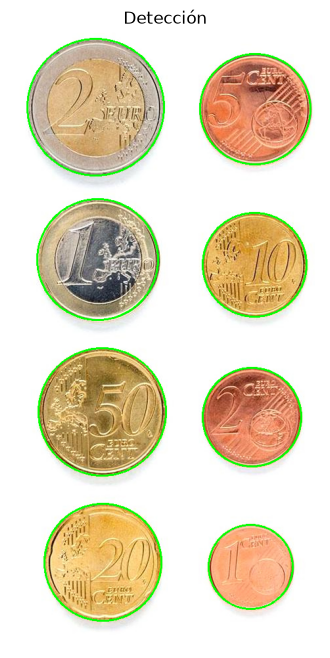

In [5]:
FICHERO = 'Monedas.jpg'
img = cv2.imread(FICHERO)
assert img is not None, f'No se encuentra {FICHERO} en {__import__("os").getcwd()}'
print(img.shape)

objetos = detectar_objetos(img)
print('Objetos detectados:', len(objetos))
vis = img.copy()
for o in objetos:
    cv2.circle(vis, (int(o['c'][0]), int(o['c'][1])), int(o['d_px'] / 2), (0, 255, 0), 2)
plt.figure(figsize=(5, 8)); plt.axis('off'); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.title('Detección'); plt.show()

### 5.2 Calibración interactiva
Se abre una ventana de OpenCV: **haz clic sobre una moneda de 1 €** y pulsa cualquier tecla. Si no hay entorno gráfico (Colab, servidor remoto…) se usa `CLIC_MANUAL = (x, y)`: coordenadas de una moneda de 1 € en la imagen.

In [6]:
CLIC_MANUAL = None   # p.ej. (62, 145). Si es None se intenta el clic interactivo

def pedir_clic(imagen, titulo='Haz clic en una moneda de 1 EUR y pulsa una tecla'):
    punto = []
    def cb(ev, x, y, flags, param):
        if ev == cv2.EVENT_LBUTTONDOWN:
            punto[:] = [x, y]
            tmp = imagen.copy(); cv2.circle(tmp, (x, y), 5, (0, 0, 255), -1); cv2.imshow(titulo, tmp)
    cv2.namedWindow(titulo, cv2.WINDOW_NORMAL)
    cv2.imshow(titulo, imagen); cv2.setMouseCallback(titulo, cb)
    cv2.waitKey(0); cv2.destroyAllWindows(); cv2.waitKey(1)
    return tuple(punto) if punto else None

clic = CLIC_MANUAL
if clic is None:
    try:
        clic = pedir_clic(img)
    except cv2.error as e:
        print('Sin entorno gráfico; define CLIC_MANUAL. (', str(e)[:60], ')')
assert clic is not None, 'No se ha hecho clic: define CLIC_MANUAL = (x, y)'

ref = objeto_en_punto(objetos, *clic)
assert ref is not None, 'El clic no cae sobre ninguna moneda detectada'
px_por_mm = ref['d_px'] / D_REF
print(f'Clic en {clic} -> diámetro {ref["d_px"]:.1f} px = {D_REF} mm  =>  {px_por_mm:.3f} px/mm')

Clic en (123, 347) -> diámetro 185.7 px = 23.25 mm  =>  7.988 px/mm


### 5.3 Clasificación y cantidad de dinero

(  130,  114)  d=26.05 mm  grupo=bimetal  -> 2€  (err +0.30 mm)
(  373,  118)  d=21.18 mm  grupo=cobre    -> 5c  (err -0.07 mm)
(  134,  347)  d=23.25 mm  grupo=bimetal  -> 1€  (err +0.00 mm)
(  373,  355)  d=19.85 mm  grupo=oro      -> 10c  (err +0.10 mm)
(  140,  578)  d=24.34 mm  grupo=oro      -> 50c  (err -0.01 mm)
(  368,  587)  d=19.00 mm  grupo=cobre    -> 2c  (err +0.25 mm)
(  141,  807)  d=22.42 mm  grupo=oro      -> 20c  (err +0.17 mm)
(  366,  815)  d=16.20 mm  grupo=cobre    -> 1c  (err -0.05 mm)

Monedas: 8   TOTAL = 3.88 €


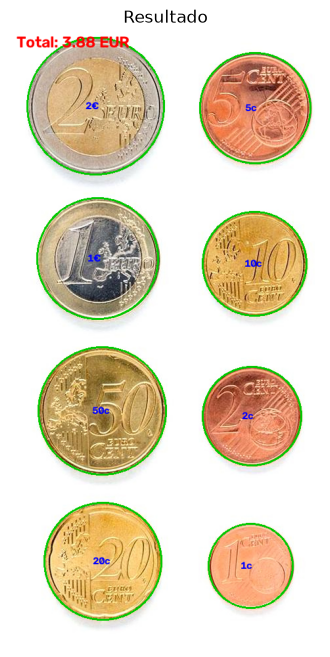

In [7]:
objetos = clasificar(img, objetos, px_por_mm)
for o in sorted(objetos, key=lambda o: (o['c'][1], o['c'][0])):
    print(f"({o['c'][0]:5.0f},{o['c'][1]:5.0f})  d={o['d_mm']:5.2f} mm  grupo={o['grupo']:8s} -> {o['tipo']}  (err {o['error_mm']:+.2f} mm)")

print(f'\nMonedas: {sum(o["tipo"] is not None for o in objetos)}   TOTAL = {total_euros(objetos):.2f} €')
plt.figure(figsize=(5, 8)); plt.axis('off')
plt.imshow(cv2.cvtColor(dibujar(img, objetos), cv2.COLOR_BGR2RGB)); plt.title('Resultado'); plt.show()

## 6. Demostrador en vivo (cámara)
Controles en la ventana: **clic** sobre una moneda de 1 € = calibrar · **r** = borrar calibración · **espacio** = congelar/descongelar · **q** o **Esc** = salir.

Ejecutar en local (necesita entorno gráfico y webcam). `FUENTE = 0` es la cámara por defecto; puede ser también la ruta a un vídeo.

In [9]:
FUENTE = 0

def demo_en_vivo(fuente=0, ancho=960):
    cap = cv2.VideoCapture(fuente)
    if not cap.isOpened():
        print('No se pudo abrir la cámara/vídeo'); return
    estado = dict(px_mm=None, clic=None)
    def cb(ev, x, y, flags, param):
        if ev == cv2.EVENT_LBUTTONDOWN:
            estado['clic'] = (x, y)
    ventana = 'Monedas en vivo'
    cv2.namedWindow(ventana); cv2.setMouseCallback(ventana, cb)
    congelado, ultimo = False, None
    suave = []                            # suaviza el total con la moda de los últimos fotogramas
    while True:
        if not congelado:
            ok, frame = cap.read()
            if not ok: break
            if frame.shape[1] > ancho:
                frame = cv2.resize(frame, (ancho, int(frame.shape[0] * ancho / frame.shape[1])))
            objs = detectar_objetos(frame, area_min=400)
            if estado['clic'] is not None:
                ref = objeto_en_punto(objs, *estado['clic'])
                if ref is not None:
                    estado['px_mm'] = ref['d_px'] / D_REF
                estado['clic'] = None
            if estado['px_mm'] is None:
                out = frame.copy()
                for o in objs:
                    cv2.circle(out, (int(o['c'][0]), int(o['c'][1])), int(o['d_px'] / 2), (0, 255, 255), 2)
                cv2.putText(out, 'Haz clic en una moneda de 1 EUR para calibrar', (10, 25),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
            else:
                objs = clasificar(frame, objs, estado['px_mm'])
                suave = (suave + [total_euros(objs)])[-7:]
                out = dibujar(frame, objs)
                cv2.putText(out, f'Estable: {max(set(suave), key=suave.count):.2f} EUR', (10, 55),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 120, 0), 2)
            ultimo = out
        cv2.imshow(ventana, ultimo)
        k = cv2.waitKey(1) & 0xFF
        if k in (ord('q'), 27): break
        if k == ord('r'): estado['px_mm'] = None; suave = []
        if k == 32: congelado = not congelado
    cap.release(); cv2.destroyAllWindows(); cv2.waitKey(1)

demo_en_vivo(FUENTE)   # <- descomenta para ejecutar

## 7. Discusión: ¿funciona? ¿qué problemas se observan?
- **Imagen ideal:** con fondo blanco y buena iluminación la segmentación es limpia y la clasificación diámetro+color es correcta. Usar solo el diámetro confundiría monedas cercanas (1 € 23,25 mm vs 20 c 22,25 mm; 5 c 21,25 vs 20 c 22,25), por eso se añade el color.
- **Cámara en vivo:** los principales problemas son (i) la **calibración** solo es válida si las monedas están a la misma distancia/plano que la de referencia y la cámara es perpendicular a la mesa (perspectiva distorsiona el diámetro); (ii) **iluminación**: reflejos y sombras alteran el umbral y el tono (se pueden ajustar `TONO_COBRE_MAX`, etc.); (iii) el **ruido** hace oscilar el total entre fotogramas (se suaviza con la moda de los últimos 7); (iv) fondos no uniformes rompen la segmentación por Otsu.
- **Objetos que no son monedas:** se descartan por baja circularidad y por diámetro fuera de tolerancia (>2 mm del tipo más cercano); un objeto circular de tamaño parecido a una moneda sí se contaría.
- **Solapes:** se separan con transformada de distancia + watershed y el radio se estima por la distancia máxima al borde; funciona con solapes ligeros, falla con solapes grandes o más de dos monedas apiladas.